# Turn reproducible evidence into a clear manuscript

This notebook maps the completed experiments to the new draft03, verifies central numbers, and distinguishes measured results from proposed extensions.

In [1]:
from pathlib import Path
import sys, json, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
candidates = [Path.cwd(), *Path.cwd().parents]
PROJECT = next((p for p in candidates if (p/'worldmodels/v2_data.py').is_file()), None)
if PROJECT is None:
    PROJECT = next(p/'experiments/aaai-worldmodels' for p in candidates if (p/'experiments/aaai-worldmodels/worldmodels/v2_data.py').is_file())
sys.path.insert(0, str(PROJECT))
REPOSITORY = PROJECT.parents[1]
from worldmodels.v2_data import load_cohort
from worldmodels import v2_evaluation as ev
from worldmodels import v2_models as models
from worldmodels.v2_runner import window_errors, verify_freeze
COHORT = PROJECT/'artifacts/runs/reference-v2-cohort-v1'
RUN = PROJECT/'artifacts/runs/reference-v2-core-v1'
TRANSFER = PROJECT/'artifacts/runs/reference-v2-transfer-v1'
FIGURES = PROJECT/'artifacts/executed-reference-v2/figures'
FIGURES.mkdir(parents=True, exist_ok=True)
USED_INPUTS={}
def sha(path): return hashlib.sha256(Path(path).read_bytes()).hexdigest()
def record_input(path):
    path=Path(path).resolve()
    key=str(path.relative_to(REPOSITORY)) if path.is_relative_to(REPOSITORY) else str(path)
    USED_INPUTS[key]=sha(path)
def read_json(path):
    path = Path(path)
    assert path.is_file(), f'Required completed artifact is absent: {path}. Read docs/reference_v2/README.md for prerequisites.'
    record_input(path)
    return json.loads(path.read_text())
def read_csv(path, **kwargs):
    record_input(path)
    return pd.read_csv(path, **kwargs)
def artifact(name, directory=RUN):
    path = directory/name
    manifest = read_json(directory/'artifact_hashes.json')
    assert name in manifest and path.is_file(), f'Unrecorded or missing artifact: {path}'
    assert sha(path) == manifest[name], f'Artifact hash differs from the completed run: {path}'
    record_input(path)
    return path
def completed_run():
    result = read_json(artifact('results.json'))
    assert result['status']=='complete' and not result.get('test_only', False)
    return result
def save_figure(figure, name):
    figure.savefig(FIGURES/(name+'.svg'), bbox_inches='tight')
    figure.savefig(FIGURES/(name+'.png'), dpi=150, bbox_inches='tight')
freeze = verify_freeze()
record_input(PROJECT/'docs/reference_v2/protocol_freeze.json')
x, valid, metadata, actual_times = load_cohort(COHORT, verify=True)
cohort_identity=read_json(COHORT/'identity.json');record_input(COHORT/'cohort.csv')
for name in cohort_identity['prepared_inputs']:
    record_input(REPOSITORY/cohort_identity['prepared_directory']/name)
assert x.shape == (len(metadata),24,16,2) and len(metadata)==2815
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':11,'svg.fonttype':'none','axes.spines.top':False,'axes.spines.right':False})
print('Verified real observations:',metadata.sequence_id.nunique(),'unique gait sequences;',len(metadata),'windows in',metadata.source_id.nunique(),'recording groups.')
print('Observation units: pelvis-relative 2D coordinates divided by a prefix torso scale. Times are decoder seconds.')


Verified real observations: 456 unique gait sequences; 2815 windows in 91 recording groups.
Observation units: pelvis-relative 2D coordinates divided by a prefix torso scale. Times are decoder seconds.


## Lead with gait sequences and explain the clinical-video scale

GAVD was introduced as the largest publicly accessible collection of abnormal-gait videos annotated by expert clinicians. That is an attributed claim about a video collection, rather than a current ranking across all gait-measurement technologies. Our benchmark evaluates 456 unique annotated gait sequences, including 141 normal sequences, through 2,815 forecast windows. These sequences are movement observations. Their 91 original recordings define the groups that stay together in evaluation, and recording identifiers do not establish patient identity.

A manuscript claim needs a measured result and an exact input identity. We read the primary-source scale review, the annotation audit, and the new reporting ledger so the presentation can explain its observation count without treating repeated observations as independent people.

In [2]:
result=completed_run()
manuscript=PROJECT/'docs/draft03'
scale_review=read_json(manuscript/'reviewer_support/literature_scale.json')
sequence_audit=read_json(manuscript/'reviewer_support/sequence_audit.json')
statistical_review=read_json(manuscript/'reviewer_support/statistical_review.json')
normal_metadata=metadata.loc[metadata.label.eq('normal')]
counts={'unique_gait_sequences':metadata.sequence_id.nunique(),'normal_gait_sequences':normal_metadata.sequence_id.nunique(),
        'forecast_windows':len(metadata),'recording_groups':metadata.source_id.nunique(),
        'normal_recording_groups':normal_metadata.source_id.nunique()}
assert counts=={'unique_gait_sequences':456,'normal_gait_sequences':141,'forecast_windows':2815,
                'recording_groups':91,'normal_recording_groups':29}
display(pd.DataFrame.from_dict(counts,orient='index',columns=['count']))
print('Primary-source scale review:',scale_review['identity'])
print('Annotation audit:',sequence_audit['analysis_identity'])
print('Statistical review:',statistical_review['identity'])
claims=read_json(manuscript/'claim_ledger.json')
assert isinstance(claims,dict) and isinstance(claims['claims'],list)
assert claims['identity']=='medwm-reference-v2-draft03-evidence-v2','The revised reporting evidence is required.'
print('Manuscript evidence identity:',claims['identity'])
display(pd.DataFrame(claims['claims'])[['id','claim','artifact','scope']])
print('The preserved previous manuscript is docs/draft02. This notebook reads only the new draft03.')


,count
unique_gait_sequences,456
normal_gait_sequences,141
forecast_windows,2815
recording_groups,91
normal_recording_groups,29


Primary-source scale review: draft03-scale-primary-literature-v1
Annotation audit: draft03-sequence-contract-audit-v1
Statistical review: draft03-independent-statistical-scale-review-v1
Manuscript evidence identity: medwm-reference-v2-draft03-evidence-v2


,id,claim,artifact,scope
0,C0,GAVD was introduced as the largest publicly ac...,GAVD primary paper/repository; reviewer_suppor...,Attributed video-specific size claim. Full cat...
1,C1,A compact current-posture transition reduces n...,reference-v2-core-v1/results.json:forecast_con...,141 normal GAVD gait sequences in 29 original ...
2,C2,The tested structured masks do not improve on ...,reference-v2-core-v1/results.json:forecast_con...,"One compact model,40% eligible-token masking,t..."
3,C3,The locked conditional two-sided score does no...,reference-v2-core-v1/results.json:primary_anom...,GAVD source groups and separate external datas...
4,C4,"The benchmark makes forecast utility, anomaly ...","Protocol freeze,complete candidate registry,cl...",Reproducibility and evaluation contribution; n...
5,C5,Post hoc equal-sequence weighting retains the ...,reference-v2-sequence-scale-posthoc-v2/results...,141 normal sequence means; whole-component res...


The preserved previous manuscript is docs/draft02. This notebook reads only the new draft03.


## Separate sequence coverage from the uncertainty unit

Several gait sequences can come from one recording, and some different sequence identifiers share video frames. The retained audit finds 17 overlapping sequence pairs. A distinct identifier or a single-direction walking annotation does not establish an independent participant. The annotation contract describes walking in one camera-relative direction; this study has not visually reverified turns in every sequence. The original primary forecast mean gives each normal recording group equal weight. A separately declared post hoc sensitivity gives each normal sequence equal weight while still resampling whole recording groups. It changes the weighting question, not the observations, fitted model, primary endpoint, or number of independent groups.

We show both forecast summaries with their identities and retain the original anomaly comparison against low motion. Forecast improvement and abnormality ranking remain separate questions.

In [3]:
source=read_csv(artifact('source_anomaly_scores.csv'))
assert result['windows']==len(metadata) and result['sources']==metadata.source_id.nunique()
assert result['normal_sources']==metadata.loc[metadata.label.eq('normal'),'source_id'].nunique()
np.testing.assert_allclose(source.low_motion,-source.persistence)
computed=ev.within_fold_summary(source,'calibrated_two_sided')['pair_weighted_auroc']
np.testing.assert_allclose(computed,result['primary_anomaly']['candidate_auroc'],atol=1e-12,rtol=0)
display(pd.DataFrame(result['forecast_contrasts']).query("method=='ridge_posture_velocity'"))
display({name:result[name] for name in ['primary_anomaly','posture_calibration_contrast']})
overlap=sequence_audit['populations']['retained_sequences']['raw_annotation_overlap']
assert overlap['unordered_same_source_sequence_pairs_sharing_exact_annotation_frames']==17
display({'different_sequence_pairs_sharing_frames':17,'participating_sequences':overlap['participating_sequences'],
         'fold_grouping':sequence_audit['fold_integrity']})
SEQUENCE_SCALE=PROJECT/'artifacts/runs/reference-v2-sequence-scale-posthoc-v2'
sequence_sensitivity=read_json(artifact('results.json',SEQUENCE_SCALE))
assert sequence_sensitivity['identity']=='reference-v2-sequence-scale-posthoc-v2' and sequence_sensitivity['status']=='complete'
assert sequence_sensitivity['forecast_refit'] is False
sequence_errors=read_csv(artifact('per_sequence_errors.csv',SEQUENCE_SCALE))
assert sequence_errors.sequence_id.is_unique and len(sequence_errors)==456
membership_columns=['source_id','sequence_id','label','component_id','outer_fold']
expected_membership=metadata[membership_columns].drop_duplicates().sort_values('sequence_id').reset_index(drop=True)
actual_membership=sequence_errors[membership_columns].sort_values('sequence_id').reset_index(drop=True)
pd.testing.assert_frame_equal(actual_membership,expected_membership,check_dtype=False)
normal_sequence_errors=sequence_errors.loc[sequence_errors.label.eq('normal')]
assert len(normal_sequence_errors)==141 and normal_sequence_errors.component_id.nunique()==29
for arm in ['persistence','ridge_posture']:
    np.testing.assert_allclose(normal_sequence_errors[arm].mean(),sequence_sensitivity['sequence_weighted_mse'][arm],atol=1e-12,rtol=0)
primary_forecast=next(row for row in result['forecast_contrasts'] if row['method']=='ridge_posture' and row['reference']=='persistence')
np.testing.assert_allclose(sequence_sensitivity['recording_weighted_primary']['relative_reduction'],primary_forecast['relative_reduction'],atol=1e-12,rtol=0)
display(pd.DataFrame([
    {'weighting':'Equal original recording groups','status':'Original primary forecast endpoint','relative_reduction_percent':100*primary_forecast['relative_reduction'],
     'conditional_interval_percent':(100*np.asarray(primary_forecast['relative_ci95'])).tolist(),'normal_sequences':141,'resampled_recording_groups':29},
    {'weighting':'Equal annotated gait sequences','status':'Separate post hoc weighting sensitivity','relative_reduction_percent':100*sequence_sensitivity['relative_reduction'],
     'conditional_interval_percent':(100*np.asarray(sequence_sensitivity['relative_ci95'])).tolist(),'normal_sequences':141,'resampled_recording_groups':29},
]))
print('Sensitivity identity:',sequence_sensitivity['identity'])
print('Uncertainty resamples:',sequence_sensitivity['resampling'])
print('The equal-sequence sensitivity is not a new cohort or a replacement for the original recording-weighted primary result.')


,method,reference,method_mse,reference_mse,estimate,ci95,method_ci95,relative_reduction,relative_ci95,normal_components,resamples,seed,positive_favors,uncertainty
33,ridge_posture_velocity,persistence,0.076933,0.121262,0.044329,"[0.028560635103812893, 0.0618197978252353]","[0.06095785479246078, 0.09349190241837674]",0.365562,"[0.27945784585038175, 0.44074667523543637]",29,5000,5702,ridge_posture_velocity,Conditional on saved cross-validation predictions
37,ridge_posture_velocity,ridge_posture,0.076933,0.071742,-0.005192,"[-0.010224247088882555, -0.00045603380387920555]","[0.06095785479246078, 0.09349190241837674]",-0.072365,"[-0.15093390760846645, -0.005846145469556964]",29,5000,5702,ridge_posture_velocity,Conditional on saved cross-validation predictions


{'primary_anomaly': {'candidate': 'calibrated_two_sided',
  'reference': 'low_motion',
  'estimate': -0.3481894150417827,
  'candidate_auroc': 0.4623955431754875,
  'reference_auroc': 0.8105849582172702,
  'ci95': [-0.5055710306406684, -0.19080779944289694],
  'candidate_ci95': [0.3245125348189415, 0.5988857938718662],
  'reference_ci95': [0.7075208913649025, 0.9025069637883009],
  'folds': [{'fold': 0,
    'normal': 6,
    'abnormal': 13,
    'candidate_auroc': 0.44871794871794873,
    'reference_auroc': 0.9102564102564102,
    'difference': -0.4615384615384615,
    'pairs': 78},
   {'fold': 1,
    'normal': 6,
    'abnormal': 12,
    'candidate_auroc': 0.6041666666666666,
    'reference_auroc': 0.9305555555555556,
    'difference': -0.32638888888888895,
    'pairs': 72},
   {'fold': 2,
    'normal': 6,
    'abnormal': 12,
    'candidate_auroc': 0.4027777777777778,
    'reference_auroc': 0.8333333333333334,
    'difference': -0.4305555555555556,
    'pairs': 72},
   {'fold': 3,
    'n

{'different_sequence_pairs_sharing_frames': 17,
 'participating_sequences': 34,
 'fold_grouping': {'source_ids_in_multiple_outer_folds': 0,
  'sequence_ids_in_multiple_outer_folds': 0,
  'components_in_multiple_outer_folds': 0,
  'retained_source_components': 91,
  'source_count': 91}}

,weighting,status,relative_reduction_percent,conditional_interval_percent,normal_sequences,resampled_recording_groups
0,Equal original recording groups,Original primary forecast endpoint,40.837469,"[33.30860590138599, 47.435018625164716]",141,29
1,Equal annotated gait sequences,Separate post hoc weighting sensitivity,41.630616,"[35.93753110159124, 46.87267133446003]",141,29


Sensitivity identity: reference-v2-sequence-scale-posthoc-v2
Uncertainty resamples: Whole recording components within original folds; all sequences and multiplicities retained.
The equal-sequence sensitivity is not a new cohort or a replacement for the original recording-weighted primary result.


## Rebuild every manuscript table from its source results

The publication tables are formatted views of the completed runs. We reconstruct all six tables from source-level summaries and cohort memberships, then compare every cell with the manuscript CSV. The renderer supplies names and decimal formatting, while the numerical values come from the declared evidence. This computation writes only into the notebook's own output area.

In [4]:
import importlib.util
renderer_path=PROJECT/'scripts/build_next_draft03.py';record_input(renderer_path)
sys.path.insert(0,str(PROJECT/'scripts'))
specification=importlib.util.spec_from_file_location('medwm_publication_renderer',renderer_path)
renderer=importlib.util.module_from_spec(specification);specification.loader.exec_module(renderer)
transfer=read_json(artifact('results.json',TRANSFER))
external_windows=read_csv(artifact('window_metadata.csv',TRANSFER))
mean_priors=read_json(artifact('results.json',PROJECT/'artifacts/runs/reference-v2-mean-prior-posthoc-v1'))
forecasts={row['arm']:row for row in result['normal_forecast'] if row['horizon']==8}
for row in mean_priors['comparisons']:
    if row['reference']=='persistence':
        forecasts[row['method']]={'mse':row['method_mse'],'ci95':row['method_ci95']}
ranks={row['score']:row for row in result['rankings']}
forecast_arms=['persistence','damped_velocity','own','bilateral','static','ridge_posture','ridge_posture_velocity','untrained_probe','mean_pose','mean_residual']
anomaly_arms=['calibrated_two_sided','posture_two_sided','low_motion','one_sided','marginal_two_sided','posture_distance','motion_quality_distance','negative_prefix_motion','high_prefix_missingness','excess_bilateral','excess_ridge_posture_velocity']
def forecast_row(arm):
    row=forecasts[arm]
    return [renderer.name(arm),renderer.fmt(row['mse']*1000,2),renderer.interval(np.array(row['ci95'])*1000,2)]
table_rows={
    'cohort':[[label,str(group.sequence_id.nunique()),str(len(group)),str(group.source_id.nunique())] for label,group in metadata.groupby('label')],
    'external_cohort':[[label,str(group.participant_id.nunique()),str(group.recording_id.nunique()),str(len(group))] for label,group in external_windows.groupby('label')],
    'forecasts':[forecast_row(arm) for arm in forecast_arms],
    'complete_forecasts':[forecast_row(arm) for arm in forecasts],
    'rankings':[[renderer.SCORES[arm],renderer.fmt(ranks[arm]['within_fold']['pair_weighted_auroc']),renderer.fmt(ranks[arm]['pooled']['auroc']),renderer.fmt(ranks[arm]['pooled']['average_precision'])] for arm in anomaly_arms],
    'external_rankings':[[renderer.name(arm),renderer.fmt(row['auroc']),renderer.interval(row['auroc_ci95']),renderer.fmt(row['average_precision'])] for arm,row in transfer['anomaly_scores'].items()],
}
rebuild=PROJECT/'artifacts/executed-reference-v2/manuscript_rebuild';rebuild.mkdir(parents=True,exist_ok=True)
table_checks=[]
for name,rows in table_rows.items():
    published=read_csv(manuscript/(name+'.csv'),dtype=str)
    if name=='cohort':
        assert published.columns.tolist()==['GAVD annotation','Sequences','Windows','Recordings']
    rebuilt=pd.DataFrame(rows,columns=published.columns).astype(str)
    pd.testing.assert_frame_equal(rebuilt,published)
    rebuilt.to_csv(rebuild/(name+'.csv'),index=False)
    table_checks.append({'table':name,'rows':len(rebuilt),'all_cells_match':True})
display(pd.DataFrame(table_checks))


,table,rows,all_cells_match
0,cohort,5,True
1,external_cohort,3,True
2,forecasts,10,True
3,complete_forecasts,40,True
4,rankings,11,True
5,external_rankings,9,True


## Keep the evidence states visible

Successful software checks, fitted models, evaluated predictions, and proposed methods are different accomplishments. The execution ledger records what actually ran. We retain an exact copy of the coordinator's ledger at execution time because its administrative acceptance status can change afterward. A latent or stochastic model must not appear as a measured contribution merely because its illustration or mathematical idea was described.

In [5]:
ledger_bytes=(PROJECT/'docs/reference_v2/run_record.json').read_bytes()
ledger_digest=hashlib.sha256(ledger_bytes).hexdigest()
ledger_snapshot=PROJECT/'artifacts/executed-reference-v2/inputs'/f'coordinator_ledger_{ledger_digest}.json'
ledger_snapshot.parent.mkdir(parents=True,exist_ok=True)
if ledger_snapshot.exists():
    assert ledger_snapshot.read_bytes()==ledger_bytes
else:
    ledger_snapshot.write_bytes(ledger_bytes)
record=read_json(ledger_snapshot)
print('Exact coordinator ledger snapshot:',ledger_digest)
request=read_json(artifact('request.json'));configuration=request['config']
ledger=read_json(artifact('model_fit_ledger.json'))
available=set(read_csv(artifact('refs_source_scores.csv')).arm) | set(read_csv(artifact('masks_source_scores.csv')).arm)
registry=[]
references=['persistence','damped_velocity','own','bilateral','shifted','static','ridge_posture','ridge_posture_velocity']
if configuration['untrained_probe']: references.append('untrained_probe')
for name in references:
    analytic=name in ['persistence','damped_velocity']
    registry.append({'candidate':name,'family':'reference','declared':True,'fitting':'analytic reference' if analytic else 'fitted normal-only model',
                     'status':'evaluated' if name in available else 'MISSING from completed evaluation; inspect run ledger'})
for policy in configuration['policies']:
    for seed in configuration['seeds']:
        name=f'mlp_{policy}_seed{seed}'
        roles=[f'outer{fold}:mask_{policy}:seed{seed}' for fold in range(5)]
        fitted=sum(any(role in item['roles'] for item in ledger.values()) for role in roles)
        registry.append({'candidate':name,'family':'mask policy and optimization seed','declared':True,'fitting':f'{fitted}/5 outer refits recorded',
                         'status':'evaluated' if name in available else 'MISSING from completed evaluation; inspect run ledger'})
    name=f'mlp_{policy}'
    registry.append({'candidate':name,'family':'fixed seed-mean prediction','declared':True,'fitting':'mean of the three declared coordinate predictions',
                     'status':'evaluated' if name in available else 'MISSING from completed evaluation; inspect run ledger'})
if 'motion_balanced' in configuration['policies']:
    registry.append({'candidate':'mlp_pattern_only','family':'mask-pattern residual diagnostic','declared':True,'fitting':'normal-only seed 27',
                     'status':'evaluated' if 'mlp_pattern_only' in available else 'MISSING from completed evaluation; inspect run ledger'})
for name in ['calibration_models.json','posture_calibration_models.json']:
    models_record=read_json(artifact(name))
    registry.append({'candidate':name,'family':'normal-reference calibration ensemble','declared':True,'fitting':f'{len(models_record)}/15 components recorded',
                     'status':'evaluated' if len(models_record)==15 else 'INCOMPLETE; inspect run ledger'})
mean_priors=read_json(artifact('results.json',PROJECT/'artifacts/runs/reference-v2-mean-prior-posthoc-v1'))
for name in ['mean_pose','mean_residual']:
    registry.append({'candidate':name,'family':'separately declared post hoc mean-prior control','declared':True,
                     'fitting':'five untuned normal-only outer fits','status':mean_priors['status']})
with pd.option_context('display.max_rows',None,'display.max_colwidth',None):
    display(pd.DataFrame(registry))
    display(pd.DataFrame([{'score':item['score'],'status':'evaluated with its declared direction',
                           'within_fold_AUROC':item['within_fold']['pair_weighted_auroc']}
                          for item in result['rankings']]))
floor_sensitivity=read_json(artifact('results.json',PROJECT/'artifacts/runs/reference-v2-floor-posthoc-v2'))
display({'separate_posthoc_analysis':floor_sensitivity['identity'],'status':floor_sensitivity['status'],
         'frozen_floors':floor_sensitivity['floors'],'forecast_refit':floor_sensitivity['forecasts_refit']})
display(pd.DataFrame([{'floor':row['floor'],'maximum_score_change':row['max_abs_score_change_vs_1e8'],
                       'changed_rank_pairs':row['ranking_agreement_vs_1e8']['changed_pair_directions'],
                       'within_fold_AUROC':row['primary_anomaly']['candidate_auroc']}
                      for row in floor_sensitivity['results']]))
print(floor_sensitivity['serialization'])
print('The failed first floor replay is preserved under its original identity. Its guard exposed an omitted CSV round trip; the revised sensitivity reproduces the exact producer path without altering the frozen scores.')
failed_floor=read_json(PROJECT/'artifacts/runs/reference-v2-floor-posthoc-v1/failure.json')
display({'preserved_attempt':failed_floor['identity'],'status':failed_floor['status'],'cause':failed_floor['cause']})
display({'separate_posthoc_analysis':sequence_sensitivity['identity'],'status':sequence_sensitivity['status'],
         'forecast_refit':sequence_sensitivity['forecast_refit'],'primary_recording_weighted_endpoint':'preserved'})
assert 'extension_gates' in record,'The final run ledger must state the extension-gate decisions.'
gates=record['extension_gates']
display(pd.DataFrame.from_dict(gates,orient='index') if isinstance(gates,dict) else pd.DataFrame(gates))
display(record)
print('Notebook 23 includes an explicitly labeled real training demonstration. Its training error is absent from the held-out result table.')
print('Read the resource/extension gate record before describing deferred models as implemented or evaluated.')


Exact coordinator ledger snapshot: e0d63578ac3e574083b916a8419d9e7527fff558d8a30d043d15ae3acade8a24


,candidate,family,declared,fitting,status
0,persistence,reference,True,analytic reference,evaluated
1,damped_velocity,reference,True,analytic reference,evaluated
2,own,reference,True,fitted normal-only model,evaluated
3,bilateral,reference,True,fitted normal-only model,evaluated
4,shifted,reference,True,fitted normal-only model,evaluated
5,static,reference,True,fitted normal-only model,evaluated
6,ridge_posture,reference,True,fitted normal-only model,evaluated
7,ridge_posture_velocity,reference,True,fitted normal-only model,evaluated
8,untrained_probe,reference,True,fitted normal-only model,evaluated
9,mlp_none_seed27,mask policy and optimization seed,True,5/5 outer refits recorded,evaluated


,score,status,within_fold_AUROC
0,calibrated_two_sided,evaluated with its declared direction,0.462396
1,posture_two_sided,evaluated with its declared direction,0.385794
2,low_motion,evaluated with its declared direction,0.810585
3,one_sided,evaluated with its declared direction,0.500000
4,marginal_two_sided,evaluated with its declared direction,0.555710
5,posture_distance,evaluated with its declared direction,0.403900
6,motion_quality_distance,evaluated with its declared direction,0.557103
7,negative_prefix_motion,evaluated with its declared direction,0.749304
8,high_prefix_missingness,evaluated with its declared direction,0.426184
9,bilateral,evaluated with its declared direction,0.289694


{'separate_posthoc_analysis': 'reference-v2-floor-posthoc-v2',
 'status': 'complete',
 'frozen_floors': [1e-10, 1e-08, 1e-06],
 'forecast_refit': False}

,floor,maximum_score_change,changed_rank_pairs,within_fold_AUROC
0,1.000000e-10,0.0,0,0.462396
1,1.000000e-08,0.0,0,0.462396
2,1.000000e-06,0.0,0,0.462396


Exactly one default pandas CSV write/read after averaging rotation scores, matching the frozen producer.
The failed first floor replay is preserved under its original identity. Its guard exposed an omitted CSV round trip; the revised sensitivity reproduces the exact producer path without altering the frozen scores.


{'preserved_attempt': 'reference-v2-floor-posthoc-v1',
 'status': 'failed_guard_before_result_export',
 'cause': 'The analysis omitted the original producer CSV write/read between rotation-score aggregation and endpoint evaluation. Raw versus parsed rational tail scores differ at most6.94e-17, changing exact near-ties.'}

{'separate_posthoc_analysis': 'reference-v2-sequence-scale-posthoc-v2',
 'status': 'complete',
 'forecast_refit': False,
 'primary_recording_weighted_endpoint': 'preserved'}

,status,reason,evidence
latent_objective,deferred,The matched coordinate experiment shows no str...,artifacts/runs/reference-v2-core-v1/results.js...
learned_masks,deferred,The simpler structured masks do not improve on...,artifacts/runs/reference-v2-core-v1/results.js...
phase_conditioning,deferred,"There is no frozen, manually validated phase e...",docs/reference_v2/protocol.md:physiology and p...
stochastic_future,deferred,The deterministic reference and masking arms h...,artifacts/runs/reference-v2-core-v1/results.js...


{'schema_version': 1,
 'run_id': 'medwm-reference-masking-v2',
 'status': 'experiments_and_publication_bundle_complete',
 'brief': {'path': 'notes/aaai-worldmodels/05-iterate-02-INSTR.md',
  'sha256': 'd28a802c245f13f8d81edc552ab098c90055b413ef60233e37b10a49c6f6dfc1'},
 'created_utc': '2026-11-16T15:59:21.512697+00:00',
 'code_revision': '5d829ec882956ad6f76c862a50b8e1cc5918761e',
 'output_root': 'experiments/aaai-worldmodels/docs/reference_v2',
 'host': {'available_agent_slots': 4,
  'architecture': 'Apple arm64',
  'memory_bytes': 34359738368,
  'cpu_count': 8},
 'resource_policy': {'max_workers': 3,
  'heavy_jobs': 1,
  'pilot_required': True,
  'initial_training_ceiling_seconds': 3600,
  'initial_external_download_ceiling_bytes': 7000000000,
  'stopping_rule': 'Complete declared core arms and source coverage once; no outcome-driven expansion. Optional phases depend on explicit scientific and feasibility gates.'},
 'decisions': ['Preserve all previous runs, draft01, draft02, noteboo

Notebook 23 includes an explicitly labeled real training demonstration. Its training error is absent from the held-out result table.
Read the resource/extension gate record before describing deferred models as implemented or evaluated.


## Verify the manuscript evidence and inspect its figures

Draft03 has editable prose and a dedicated generator. Its evidence record links numerical tables and figures to completed runs. Read figures at full size and check their captions against units, sample counts, score direction, and uncertainty. A strong contribution should be understandable without specialist vocabulary.

Evidence identity: medwm-reference-v2-draft03-evidence-v2


,count
gavd_windows,2815
gavd_sequences,456
gavd_normal_sequences,141
gavd_recording_groups,91
gavd_normal_recording_groups,29
gavd_sources,91
gavd_normal_sources,29
external_windows,773
external_recordings,168
external_coded_participants,90


{'sequence_persistence_mse': '0.13850',
 'sequence_posture_mse': '0.08084',
 'sequence_gain': '0.05766',
 'sequence_ci': '[0.04178, 0.07967]',
 'sequence_relative': '41.6',
 'posture_mse': '0.07174',
 'persistence_mse': '0.12126',
 'posture_gain': '0.04952',
 'posture_gain_ci': '[0.03447, 0.06628]',
 'posture_relative': '40.8',
 'pv_mse': '0.07693',
 'pv_posture_gain': '-0.00519',
 'pv_posture_ci': '[-0.01022, -0.00046]',
 'internal_auroc': '0.462',
 'internal_low': '0.811',
 'internal_difference': '-0.348',
 'internal_ci': '[-0.506, -0.191]',
 'external_auroc': '0.591',
 'external_low': '0.762',
 'external_difference': '-0.172',
 'external_ci': '[-0.357, 0.009]',
 'sensitivity_auroc': '0.597',
 'sensitivity_low': '0.759',
 'sensitivity_difference': '-0.162',
 'sensitivity_ci': '[-0.349, 0.020]',
 'uniform_mse': '0.07761',
 'tubes_mse': '0.07962',
 'balanced_mse': '0.07916',
 'tubes_difference': '-0.00201',
 'tubes_ci': '[-0.00426, -0.00002]',
 'balanced_difference': '-0.00155',
 'bala

{'artifacts/runs/reference-v2-core-v1/results.json': '82484bbf2db8d0f98f24e6c387c0ed8899eac1a7110437b84377590ef0ed3e3d',
 'artifacts/runs/reference-v2-core-v1/artifact_hashes.json': '4031d67bfe561fd8ebdf51a335a90bef8bad938d65fbd77184d7cd8241c1f843',
 'artifacts/runs/reference-v2-transfer-v1/results.json': 'dba163563765f460bb48e0321e70f426f12fb45e24d6d3813ecb03caa3610ee8',
 'artifacts/runs/reference-v2-transfer-v1/artifact_hashes.json': 'a2512ff0f8f787e7b7c5ff24e8167d6d2ab6f045020705d5436f307d8cdf1235',
 'artifacts/runs/reference-v2-identity-sensitivity-v1/results.json': '534eabf59f0a6eabec6daea64ef7455b792ad7cb2a63414f49f4b5cf0c311710',
 'artifacts/runs/reference-v2-identity-sensitivity-v1/artifact_hashes.json': '9d64fc61c8d1654c0fcc107dc9a042bf4afb379bace7238cec3408071681dcc8',
 'artifacts/runs/reference-v2-robustness-v1/results.json': 'b009d1e99a4b914b85849c984598160646cdbaf4b5d1baa23a9402322405b6dd',
 'artifacts/runs/reference-v2-robustness-v1/artifact_hashes.json': 'ebfef00b62add08

Manuscript PDF exists: True


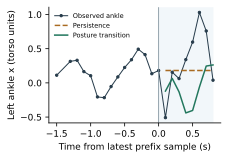

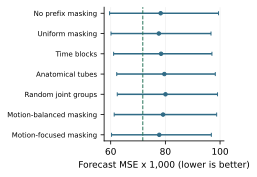

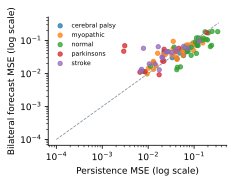

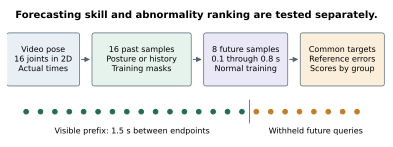

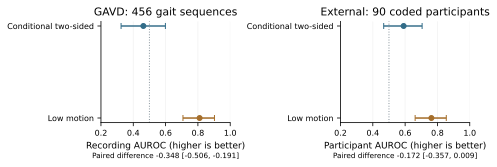

,figure,sha256,exact_svg_match
0,forecast_example.svg,23c927cf00cea24480cb24b3865fe24110171c4ea2d60f...,True
1,masking_results.svg,f2d03ad6635883abf6e0380cc7b98ecd3635f382e9f531...,True
2,motion_and_error.svg,2b2f5aa73020e559f1ad39891c2d41f323e98af534fdb9...,True
3,observation_task.svg,7fe5000851e1de0ec9a738809f87038e908512150c6b16...,True
4,ranking_comparison.svg,52c80e1a15c84be1797439925a50db4e2899a02cff24e7...,True


Read the independent final review for exact accepted artifact identities after all material edits.


In [6]:
evidence=read_json(manuscript/'evidence.json')
print('Evidence identity:',evidence['identity'])
assert evidence['identity']==claims['identity']=='medwm-reference-v2-draft03-evidence-v2'
assert evidence['run_identities']['sequence_weighting']=='artifacts/runs/reference-v2-sequence-scale-posthoc-v2'
assert evidence['counts']['gavd_sequences']==456 and evidence['counts']['gavd_normal_sequences']==141
for input_name,expected_hash in evidence['inputs'].items():
    declared_input=PROJECT/input_name
    assert sha(declared_input)==expected_hash,f'A manuscript evidence input changed: {input_name}'
    record_input(declared_input)
display(pd.DataFrame.from_dict(evidence['counts'],orient='index',columns=['count']))
display(evidence['displayed_values'])
display(evidence['inputs'])
print('Manuscript PDF exists:',(manuscript/'manuscript.pdf').is_file())
artifact('refs_predictions.npz');artifact('source_scores.csv')
renderer.OUT=rebuild;(rebuild/'figures').mkdir(exist_ok=True)
with plt.rc_context():
    plt.rcdefaults()
    renderer.figures(result,transfer,forecasts,ranks,metadata)
from IPython.display import SVG
figure_checks=[]
for figure in sorted((manuscript/'figures').glob('*.svg')):
    record_input(figure)
    regenerated=rebuild/'figures'/figure.name
    assert regenerated.is_file() and sha(regenerated)==sha(figure),f'The rebuilt figure differs: {figure.name}'
    figure_checks.append({'figure':figure.name,'sha256':sha(figure),'exact_svg_match':True})
    display(SVG(filename=str(regenerated)))
assert len(figure_checks)==5 and len(table_checks)==6
display(pd.DataFrame(figure_checks))
(PROJECT/'docs/reference_v2/notebook_26_publication_rebuild.json').write_text(json.dumps({'tables':table_checks,'figures':figure_checks,'renderer_sha256':sha(renderer_path),
    'reporting_identity':evidence['identity'],'evidence_sha256':sha(manuscript/'evidence.json'),
    'sequence_sensitivity_identity':sequence_sensitivity['identity'],'sequence_audit_identity':sequence_audit['analysis_identity']},indent=2)+'\n')
print('Read the independent final review for exact accepted artifact identities after all material edits.')


## Explain the contribution in complete sentences

The last check is conceptual. Explain the observation model, the role of its simple reference, the strongest measured finding, and the remaining generalization requirement in four connected sentences. The conclusion must match the verified comparison, including the strongest simple alternative. It should help a reader understand what has been learned and why that finding matters for future medical world models.

In [7]:
print('Evidence paths:')
for path in [RUN/'results.json',TRANSFER/'results.json',manuscript/'manuscript.pdf',PROJECT/'docs/reference_v2/protocol.md']:
    record_input(path)
    print(path.relative_to(PROJECT),sha(path))
print('The manuscript generator and independent review, rather than this notebook, determine the final publication claim.')
forecast=next(row for row in result['forecast_contrasts'] if row['method']=='ridge_posture' and row['reference']=='persistence')
print('A plain-language explanation grounded in the completed evidence follows.')
print('The study evaluates 456 unique annotated gait sequences from GAVD, including 141 normal sequences, using 2,815 windows of joint observations.')
print(f"A compact current-posture model reduced normal forecast error by {100*forecast['relative_reduction']:.1f}% relative to repeating the last pose when each original recording received equal weight.")
print(f"A separately declared post hoc analysis gave a similar {100*sequence_sensitivity['relative_reduction']:.1f}% reduction with equal sequence weights, while the masking and anomaly comparisons retained the need for stronger simple references.")
print('Uncertainty keeps related sequences together in their recording groups; these movement observations and frozen external transfer support a reproducible benchmark, while patient-level use still requires independent clinical validation.')

# Retain the exact inputs used by this independent-kernel execution.
input_path=PROJECT/'artifacts/executed-reference-v2/inputs/26_manuscript_evidence_and_claims.json'
input_path.parent.mkdir(parents=True,exist_ok=True)
input_path.write_text(json.dumps({'path_base':'repository root','inputs':USED_INPUTS},indent=2)+'\n')


Evidence paths:
artifacts/runs/reference-v2-core-v1/results.json 82484bbf2db8d0f98f24e6c387c0ed8899eac1a7110437b84377590ef0ed3e3d
artifacts/runs/reference-v2-transfer-v1/results.json dba163563765f460bb48e0321e70f426f12fb45e24d6d3813ecb03caa3610ee8
docs/draft03/manuscript.pdf 1c166b642ae72b9ea2451541f6a0b8f2440ec10b737664ea936e54f8afd1c6df
docs/reference_v2/protocol.md 7b7560939585a6849ccf85c9e6b096d5327bbfe6e5c50ef5b314e70ddfe1f71f
The manuscript generator and independent review, rather than this notebook, determine the final publication claim.
A plain-language explanation grounded in the completed evidence follows.
The study evaluates 456 unique annotated gait sequences from GAVD, including 141 normal sequences, using 2,815 windows of joint observations.
A compact current-posture model reduced normal forecast error by 40.8% relative to repeating the last pose when each original recording received equal weight.
A separately declared post hoc analysis gave a similar 41.6% reduction with

9384